# Práctica 2: Alineamientos con Biopython

## Imports

In [1]:
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from Bio import SeqIO, Entrez
from Bio.Align import PairwiseAligner, substitution_matrices

## Ejercicio 1: Grid Search de las penalizaciones de hueco

En *Machine Learning*, para buscar los parámetros óptimos de un modelo se puede usar *Grid Search*. Aquí, el alineador es el modelo, y las penalizaciones de huecos son los hiperparámetros.

```python
# Secuencia original de un gen sano
seq_sana     = "GCATGCATGCATGC"

# Secuencia de un gen degradado (paciente)
seq_paciente = "GCATGCGC"
```

Crear dos bucles anidados para iterar sobre un espacio de búsqueda: `open_gap` (de -1 a -20) y `extend_gap` (de -0.1 a -5.0). Elegir el intervalo.

Para cada combinación, ejecutar el `PairwiseAligner` sobre las secuencias original y mutada.

Almacenar el número de "empates óptimos" (tamaño del iterador) generados por cada combinación en un DataFrame de Pandas.

Descubrir matemáticamente en qué punto exacto del espacio paramétrico el algoritmo "colapsa" y pasa de dar múltiples empates a dar una única solución óptima. Muestre la solución obtenida.

Haga alguna aportación adicional.

> **NOTA IMPORTANTE:** Convertir un concepto biológico en un problema de optimización puro es **peligroso**.

### 1. Secuencias y parámetros
La secuencia sana tiene 14 bases y la del paciente 8, así que hacen falta como mínimo 6 huecos. Las 8 bases del paciente aparecen en la sana en el mismo orden, por lo que se pueden alinear sin ningún fallo. Lo único que hay que decidir es cómo se reparten esos 6 huecos: todos juntos en un bloque, o separados en varios bloques.

Un hueco cuesta `open_gap` al abrirse y `extend_gap` por cada hueco extra pegado a él. Un bloque de `n` huecos cuesta `open_gap + (n - 1) × extend_gap`.

Usamos el esquema `match = 5` y `mismatch = -4`, en modo global (se alinean las secuencias completas). El enunciado no fija estos valores: Biopython usa por defecto `match = 1` y `mismatch = 0`, y el profesor usa `5 / -4` en sus ejemplos. Probamos:
- `open_gap` de -1 a -20 (paso 1): 20 valores.
- `extend_gap` de -0.1 a -5.0 (paso 0.1): 50 valores.

Son 20 × 50 = **1000 combinaciones**.

In [2]:
seq_sana = "GCATGCATGCATGC"
seq_paciente = "GCATGCGC"

valores_open = list(range(-1, -21, -1))
valores_extend = [round(-0.1 * i, 1) for i in range(1, 51)]

print(f"open_gap: de {valores_open[0]} a {valores_open[-1]} ({len(valores_open)} valores)")
print(f"extend_gap: de {valores_extend[0]} a {valores_extend[-1]} ({len(valores_extend)} valores)")
print(f"Combinaciones: {len(valores_open) * len(valores_extend)}")

open_gap: de -1 a -20 (20 valores)
extend_gap: de -0.1 a -5.0 (50 valores)
Combinaciones: 1000


### 2. Grid Search con dos bucles anidados
Para cada combinación creamos un alineador, alineamos las dos secuencias y guardamos:
- `score`: la puntuación óptima.
- `n_empates`: cuántos alineamientos distintos tienen esa puntuación óptima (`len(alineamientos)`).

Todo se guarda en un DataFrame de Pandas.

In [3]:
filas = []

for open_gap in valores_open:
    for extend_gap in valores_extend:
        alineador = PairwiseAligner()
        alineador.mode = "global"
        alineador.match_score = 5
        alineador.mismatch_score = -4
        alineador.open_gap_score = open_gap
        alineador.extend_gap_score = extend_gap

        alineamientos = alineador.align(seq_sana, seq_paciente)

        filas.append({
            "open_gap": open_gap,
            "extend_gap": extend_gap,
            "score": alineamientos.score,
            "n_empates": len(alineamientos),
        })

df = pd.DataFrame(filas)
df.head()

,open_gap,extend_gap,score,n_empates
0,-1,-0.1,38.5,1
1,-1,-0.2,38.0,1
2,-1,-0.3,37.5,1
3,-1,-0.4,37.0,1
4,-1,-0.5,36.5,1


### 3. Mapa de calor de los empates
Cada casilla es una combinación de `open_gap` (filas) y `extend_gap` (columnas). El color indica cuántos alineamientos óptimos hay.

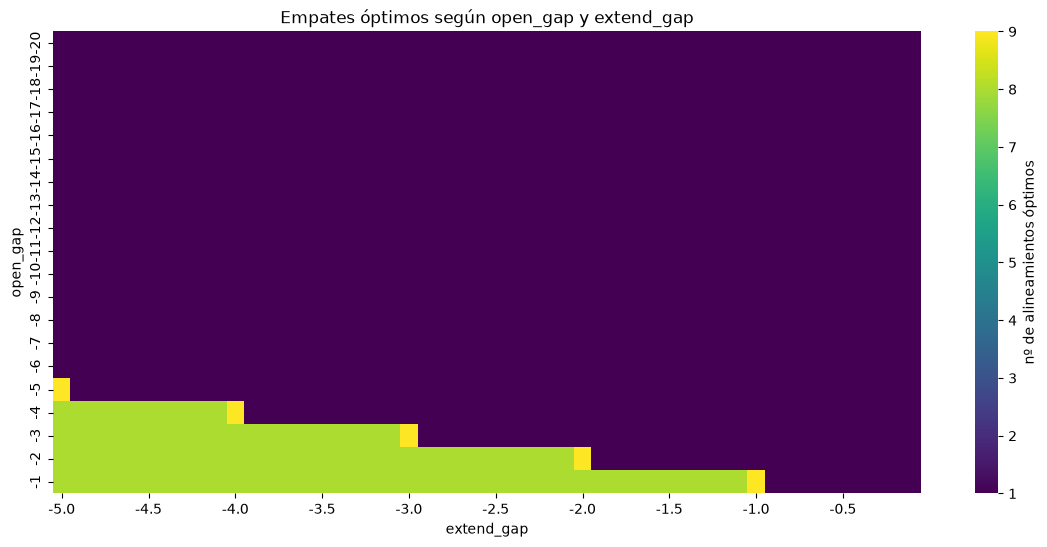

In [4]:
tabla = df.pivot(index="open_gap", columns="extend_gap", values="n_empates")

plt.figure(figsize=(14, 6))
sns.heatmap(tabla, cmap="viridis", xticklabels=5, cbar_kws={"label": "nº de alineamientos óptimos"})
plt.title("Empates óptimos según open_gap y extend_gap")
plt.xlabel("extend_gap")
plt.ylabel("open_gap")
plt.show()

### 4. ¿Dónde se pasa de empates a una única solución?
En el mapa se ve una diagonal que separa las dos zonas. Comprobamos que esa diagonal es `|extend_gap| = |open_gap|`: hay empates justo cuando extender un hueco cuesta igual o más que abrirlo, es decir, cuando `extend_gap <= open_gap` (los dos son negativos). Los tres casos concretos junto a la frontera (`-2.9`, `-3.0` y `-3.1`) se ven con su número de empates en el apartado 6.

In [5]:
hay_empates = df["n_empates"] > 1
extender_cuesta_igual_o_mas = df["extend_gap"] <= df["open_gap"]

print(f"¿Hay empates exactamente cuando |extend| >= |open|? {(hay_empates == extender_cuesta_igual_o_mas).all()}")

¿Hay empates exactamente cuando |extend| >= |open|? True


### 5. Explicación matemática
Las 8 bases del paciente coinciden: 8 × 5 = 40 puntos. Los 6 huecos se reparten en `k` bloques y cada bloque paga `open_gap` una vez. El coste total de los huecos es:

`k × open + (6 − k) × extend = 6 × extend + k × (open − extend)`

Por tanto:

**score = 40 + 6 × extend + k × (open − extend)**

Todo depende del signo de `open − extend`:
- **`|extend| < |open|`** (abrir cuesta más): `open − extend < 0`, cada bloque extra resta puntos. Gana `k = 1`, todos los huecos juntos. **Una única solución.**
- **`|extend| = |open|`**: `open − extend = 0`, el número de bloques no cambia el score. **Empatan todas las formas** (9).
- **`|extend| > |open|`** (extender cuesta más): `open − extend > 0`, cada bloque extra suma puntos. Gana el máximo de bloques posible, `k = 2`. **Empatan las formas con 2 bloques** (8).

El algoritmo "colapsa" a una única solución exactamente cuando `|extend| < |open|`: la frontera es `open = extend`. Comprobamos que la fórmula reproduce el score de Biopython en las 1000 combinaciones.

In [6]:
k = np.where(df["extend_gap"] > df["open_gap"], 1, 2)
score_teorico = 40 + 6 * df["extend_gap"] + k * (df["open_gap"] - df["extend_gap"])

print(f"¿La fórmula coincide con Biopython en las {len(df)} combinaciones? {np.isclose(df['score'], score_teorico).all()}")

¿La fórmula coincide con Biopython en las 1000 combinaciones? True


### 6. Solución obtenida
Mostramos los alineamientos óptimos para `open_gap = -3` y los tres valores de `extend_gap` junto a la frontera. Cuando hay una única solución, los 6 huecos están en un solo bloque. Cuando hay empates, hay alineamientos con los huecos repartidos en dos bloques.

In [7]:
for extend_gap in (-2.9, -3.0, -3.1):
    alineador = PairwiseAligner()
    alineador.mode = "global"
    alineador.match_score = 5
    alineador.mismatch_score = -4
    alineador.open_gap_score = -3
    alineador.extend_gap_score = extend_gap

    alineamientos = alineador.align(seq_sana, seq_paciente)
    print(f"open_gap = -3, extend_gap = {extend_gap}: {len(alineamientos)} alineamiento(s) óptimo(s), score = {alineamientos.score}")
    for alineamiento in alineamientos:
        print(alineamiento)

open_gap = -3, extend_gap = -2.9: 1 alineamiento(s) óptimo(s), score = 22.500000000000004
target            0 GCATGCATGCATGC 14
                  0 ||||||------|| 14
query             0 GCATGC------GC  8

open_gap = -3, extend_gap = -3.0: 9 alineamiento(s) óptimo(s), score = 22.0
target            0 GCATGCATGCATGC 14
                  0 ||||||--||---- 14
query             0 GCATGC--GC----  8

target            0 GCATGCATGCATGC 14
                  0 ||||||--|----| 14
query             0 GCATGC--G----C  8

target            0 GCATGCATGCATGC 14
                  0 ||||||------|| 14
query             0 GCATGC------GC  8

target            0 GCATGCATGCATGC 14
                  0 |||||----|--|| 14
query             0 GCATG----C--GC  8

target            0 GCATGCATGCATGC 14
                  0 ||||----||--|| 14
query             0 GCAT----GC--GC  8

target            0 GCATGCATGCATGC 14
                  0 |||----|||--|| 14
query             0 GCA----TGC--GC  8

target            0 GCATGCATG

### 7. Aportación adicional y conclusiones
**Aportación adicional:** hemos demostrado con una fórmula (apartado 5) por qué aparece la frontera `open = extend`, y hemos comprobado que reproduce los scores de Biopython en todas las combinaciones, en lugar de limitarnos a observarla en el mapa de calor. Además, en el apartado 8 comprobamos que el punto de colapso no depende de los valores de `match` y `mismatch`.

**Conclusiones:**
- El problema se reduce a decidir **en cuántos bloques se colocan 6 huecos**: la secuencia del paciente cabe en la sana sin fallos.
- Hay una **única solución** si `|extend| < |open|` y **varios empates** si `|extend| ≥ |open|`. El punto de colapso es `open = extend`, y no depende de `match` ni `mismatch`.
- **Es peligroso** optimizar solo para obtener una solución única: eso es una propiedad matemática, no biológica. Una deleción real suele borrar un trozo seguido, y por eso el modelo con abrir caro y extender barato es el razonable. Lo bueno no es que elimine los empates, sino que se parece a cómo ocurren las mutaciones.

### 8. ¿Importa el valor de `match` y `mismatch`?
Se puede usar `match = 1` y `mismatch = 0` (los valores por defecto). Repetimos el Grid Search completo con tres esquemas y comprobamos si los empates siguen apareciendo exactamente cuando `|extend| ≥ |open|`.

El **punto de colapso es el mismo en los tres**. Lo que sí depende del esquema es la fórmula del apartado 5: con `5 / -4` un fallo (mismatch) cuesta 9 puntos y nunca compensa, así que la fórmula es exacta en las 1000 combinaciones. Con `1 / 0` un fallo apenas cuesta, y cuando extender es mucho más caro que abrir (por ejemplo `open = -1` y `extend ≤ -2.1`) compensa aceptar fallos para evitar huecos: aparecen otros alineamientos y la fórmula deja de valer en esa zona. Por eso usamos `5 / -4` en el análisis.

In [8]:
for match, mismatch in [(5, -4), (1, 0), (2, -1)]:
    coincide = True
    for open_gap in valores_open:
        for extend_gap in valores_extend:
            alineador = PairwiseAligner()
            alineador.mode = "global"
            alineador.match_score = match
            alineador.mismatch_score = mismatch
            alineador.open_gap_score = open_gap
            alineador.extend_gap_score = extend_gap

            hay_empates = len(alineador.align(seq_sana, seq_paciente)) > 1
            if hay_empates != (extend_gap <= open_gap):
                coincide = False

    print(f"match = {match}, mismatch = {mismatch}: ¿empates exactamente cuando |extend| >= |open|? {coincide}")

match = 5, mismatch = -4: ¿empates exactamente cuando |extend| >= |open|? True
match = 1, mismatch = 0: ¿empates exactamente cuando |extend| >= |open|? True
match = 2, mismatch = -1: ¿empates exactamente cuando |extend| >= |open|? True


## Ejercicio 2: Similitud entre especies

Cargar un archivo FASTA con 5 secuencias de la misma proteína (ej. Humano, Chimpancé, Ratón, Pez, Mosca) usando `Bio.SeqIO`.

Programar un bucle de "todos contra todos" para calcular el `.score` de alineamiento global usando `BLOSUM62` entre cada par de especies.

Volcar esas 25 puntuaciones en una matriz de NumPy o un DataFrame de Pandas.

Renderizar esa matriz usando un *Heatmap* de la biblioteca Seaborn o Matplotlib.

Experimentar con otras matrices de substitución.

Comentar los resultados.

### 1. Descargar y cargar las secuencias con `Bio.SeqIO`
Usamos el **citocromo c**, una proteína conservada de la cadena respiratoria, de 5 especies:

| Especie | Código (UniProt) |
|---|---|
| Humano (*Homo sapiens*) | P99999 |
| Chimpancé (*Pan troglodytes*) | P99998 |
| Ratón (*Mus musculus*) | P62897 |
| Pez (*Danio rerio*, pez cebra) | Q6IQM2 |
| Mosca (*Drosophila melanogaster*) | P84029 |

Se descargan las cinco secuencias desde NCBI usando `Bio.Entrez` y se guardan en `datos/citocromo_c.fasta`. Después, se leen con `Bio.SeqIO` para obtener las secuencias de aminoácidos y sus identificadores.

In [9]:
load_dotenv()
Entrez.email = os.getenv("ENTREZ_EMAIL")

codigos = ["P99999", "P99998", "P62897", "Q6IQM2", "P84029"]

os.makedirs("datos", exist_ok=True)
ruta_fasta = "datos/citocromo_c.fasta"

if not os.path.exists(ruta_fasta):
    registros_descargados = []
    for codigo in codigos:
        with Entrez.efetch(db="protein", id=codigo, rettype="fasta", retmode="text") as manejador:
            registros_descargados.append(SeqIO.read(manejador, "fasta"))

    SeqIO.write(registros_descargados, ruta_fasta, "fasta")
    print(f"Descarga terminada: {ruta_fasta}")
else:
    print(f"El archivo {ruta_fasta} ya existe, no hace falta descargar.")

Descarga terminada: datos/citocromo_c.fasta


In [10]:
especies = ["Humano", "Chimpancé", "Ratón", "Pez", "Mosca"]

registros = list(SeqIO.parse(ruta_fasta, "fasta"))
assert len(registros) == len(especies)

secuencias = [registro.seq for registro in registros]

for especie, registro in zip(especies, registros):
    print(f"{especie:10s} {registro.id:12s} {len(registro.seq)} aminoácidos")

Humano     sp|P99999.2|CYC_HUMAN 105 aminoácidos
Chimpancé  sp|P99998.2|CYC_PANTR 105 aminoácidos
Ratón      sp|P62897.2|CYC_MOUSE 105 aminoácidos
Pez        sp|Q6IQM2.3|CYC_DANRE 104 aminoácidos
Mosca      sp|P84029.2|CYC2_DROME 108 aminoácidos


### 2. Todos contra todos con BLOSUM62
**¿Qué es BLOSUM62?** Es una tabla que dice cuántos puntos se da al emparejar dos aminoácidos en un alineamiento. Si son iguales o parecidos químicamente, la puntuación es positiva; si son muy distintos, negativa. Por ejemplo: `W–W = 11` (el triptófano es raro y conservarlo puntúa mucho), `L–I = 2` (leucina e isoleucina son parecidas) y `W–A = -3` (muy distintos).

Definimos la función `todos_contra_todos(nombre_matriz)`, que crea el alineador **global** con esa matriz y penalizaciones de hueco habituales en proteínas: `open_gap = -10` (abrir un hueco es caro) y `extend_gap = -0.5` (alargarlo es barato). Con dos bucles anidados alinea cada especie con todas las demás (5 × 5 = **25 puntuaciones**), incluida ella misma, y devuelve un DataFrame. Primero la usamos con `BLOSUM62`.

In [11]:
def todos_contra_todos(nombre_matriz):
    alineador = PairwiseAligner()
    alineador.mode = "global"
    alineador.substitution_matrix = substitution_matrices.load(nombre_matriz)
    alineador.open_gap_score = -10
    alineador.extend_gap_score = -0.5

    scores = np.zeros((5, 5))
    for i in range(5):
        for j in range(5):
            scores[i, j] = alineador.align(secuencias[i], secuencias[j]).score

    return pd.DataFrame(scores, index=especies, columns=especies)


df_blosum62 = todos_contra_todos("BLOSUM62")
df_blosum62

,Humano,Chimpancé,Ratón,Pez,Mosca
Humano,565.0,565.0,522.0,475.0,431.5
Chimpancé,565.0,565.0,522.0,475.0,431.5
Ratón,522.0,522.0,565.0,504.0,466.5
Pez,475.0,475.0,504.0,558.0,464.5
Mosca,431.5,431.5,466.5,464.5,578.0


### 3. Mapa de calor
Dibujamos la matriz de `BLOSUM62` con un *heatmap*. Cada casilla es la puntuación de alinear dos especies; cuanto más clara, más parecidas.

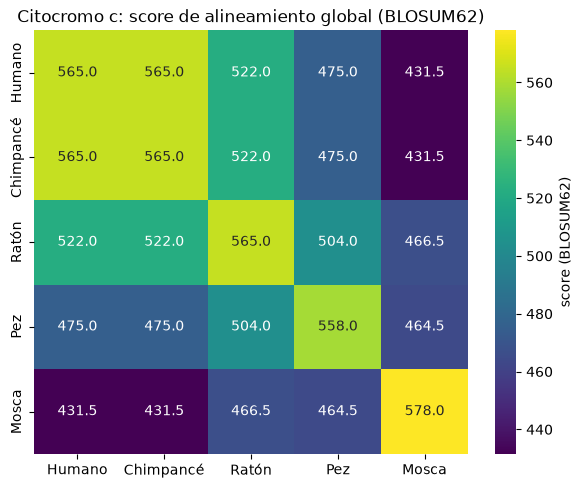

In [12]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(df_blosum62, annot=True, fmt=".1f", cmap="viridis", cbar_kws={"label": "score (BLOSUM62)"})
plt.title("Citocromo c: score de alineamiento global (BLOSUM62)")
plt.show()

### 4. Normalizar los scores
El score bruto depende de la longitud y de la composición de cada secuencia, así que la diagonal no vale igual para todas (565 frente a 558 en el pez, que tiene un aminoácido menos). Para comparar parejas de forma justa, la función `normalizar(df)` divide cada score entre la media geométrica de los scores de las dos secuencias consigo mismas (la media geométrica combina de forma equilibrada a las dos secuencias):

`score_norm(A, B) = score(A, B) / √(score(A, A) × score(B, B))`

Así la diagonal vale siempre 1 y el resto de valores queda entre 0 y 1.

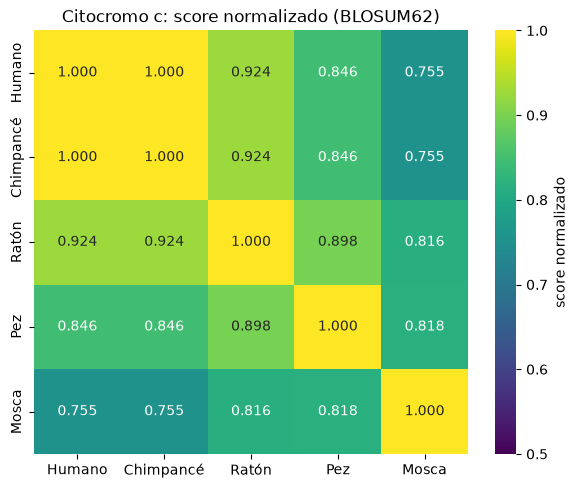

In [13]:
def normalizar(df):
    normalizado = np.zeros((5, 5))
    for i in range(5):
        for j in range(5):
            normalizado[i, j] = df.iloc[i, j] / np.sqrt(df.iloc[i, i] * df.iloc[j, j])

    return pd.DataFrame(normalizado, index=especies, columns=especies)


df_norm_blosum62 = normalizar(df_blosum62)

plt.figure(figsize=(7, 5.5))
sns.heatmap(df_norm_blosum62, annot=True, fmt=".3f", cmap="viridis", vmin=0.5, vmax=1, cbar_kws={"label": "score normalizado"})
plt.title("Citocromo c: score normalizado (BLOSUM62)")
plt.show()

### 5. Otras matrices de sustitución
Una matriz de sustitución es la tabla de puntos entre aminoácidos (BLOSUM62 es una de ellas). Probamos otras para ver si la conclusión cambia:
- `BLOSUM45` y `BLOSUM80`: como BLOSUM62, pero más permisiva (45) o más estricta (80) con los cambios de aminoácido.
- `PAM30` y `PAM250`: otra familia. PAM30 es estricta y PAM250 permisiva.

Cada matriz puntúa en una escala distinta, así que comparamos los scores **normalizados** (entre 0 y 1).

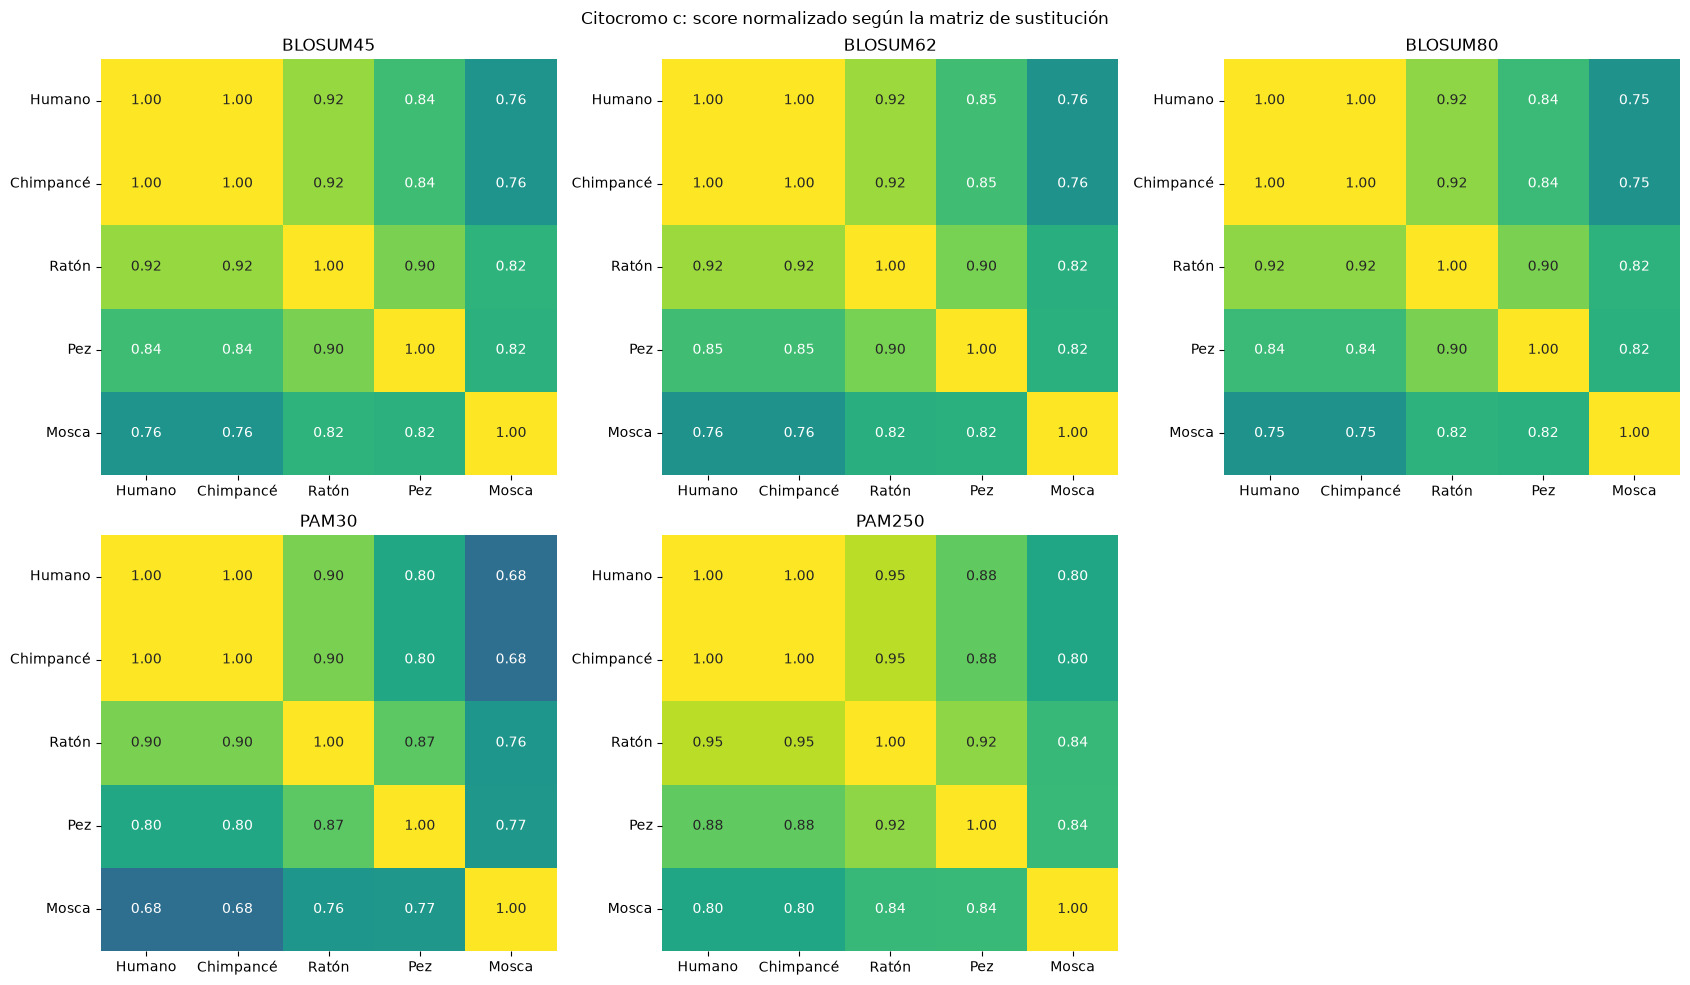

In [14]:
nombres_matrices = ["BLOSUM45", "BLOSUM62", "BLOSUM80", "PAM30", "PAM250"]
normalizados = {}

fig, ejes = plt.subplots(2, 3, figsize=(17, 10))
for nombre, eje in zip(nombres_matrices, ejes.flat):
    normalizados[nombre] = normalizar(todos_contra_todos(nombre))
    sns.heatmap(normalizados[nombre], annot=True, fmt=".2f", cmap="viridis", vmin=0.5, vmax=1, cbar=False, ax=eje)
    eje.set_title(nombre)

ejes.flat[-1].axis("off")
plt.suptitle("Citocromo c: score normalizado según la matriz de sustitución")
plt.tight_layout()
plt.show()

Comparamos la similitud de cada especie con el **humano** en todas las matrices. Las filas están ordenadas de más a menos parecido, así que si en todas las columnas los valores bajan de arriba abajo, el orden no cambia.

In [15]:
comparacion = pd.DataFrame()
for nombre in nombres_matrices:
    comparacion[nombre] = normalizados[nombre]["Humano"]

comparacion = comparacion.drop(index="Humano")
comparacion.round(3)

,BLOSUM45,BLOSUM62,BLOSUM80,PAM30,PAM250
Chimpancé,1.000,1.000,1.000,1.000,1.000
Ratón,0.921,0.924,0.916,0.899,0.948
Pez,0.844,0.846,0.839,0.797,0.878
Mosca,0.759,0.755,0.752,0.678,0.797


### 6. Comentario de los resultados
**Con BLOSUM62:**
- **Humano y chimpancé son idénticos**: su score (565) es igual al de cada uno consigo mismo, y su valor normalizado es 1. Las dos secuencias del citocromo c coinciden aminoácido a aminoácido.
- El orden de parecido sigue el árbol de la evolución: respecto al humano, el **ratón** (522) es el más cercano, luego el **pez** (475) y por último la **mosca** (431.5). La mosca es la más distinta de todas, con un valor normalizado de 0.755 frente al humano.
- La diagonal no vale igual para todos (565, 558 y 578) porque el score depende de la longitud y composición. Por eso normalizamos: así comparamos parejas de forma justa.

**Con otras matrices:**
- Los valores absolutos cambian, pero el **orden de las especies no cambia**: la conclusión biológica es la misma con las cinco.
- Las matrices "estrictas" (`PAM30`, `BLOSUM80`) separan más a la mosca (0.678 con PAM30) porque penalizan mucho los cambios de aminoácido. Las "permisivas" (`PAM250`, `BLOSUM45`) toleran más cambios y dejan a todas las especies más cerca (0.797 con PAM250).

**Conclusión:** el citocromo c está muy conservado, y el score del alineamiento global refleja bien la distancia evolutiva. La elección de la matriz cambia la escala, pero no la conclusión. Hay que tener cuidado con el score bruto: hace falta normalizar para compararlo entre secuencias de distinta longitud.

## Ejercicio 3: Escalabilidad del alineador

La programación dinámica es perfecta pero costosa. Un ingeniero de datos necesita saber si su pipeline escalará cuando pase de procesar 100 datos a procesar 1 millón.

Escribir un script que genere secuencias de ADN aleatorias (usando la librería `random` de Python) de tamaños incrementales: 100, 500, 1000, 2000 y 5000 bases.

Usar un módulo de tiempo de alto rendimiento para cronometrar en milisegundos cuánto tarda `PairwiseAligner` en alinear cada par.

Graficar (con Matplotlib) la longitud de la secuencia en el eje X y el tiempo de ejecución en el eje Y.

Interpretar el resultado obtenido.

### 1. Planteamiento
Generamos pares de secuencias de ADN aleatorias de 100, 500, 1000, 2000 y 5000 bases (con `random`, con semilla fija para que sea reproducible) y medimos cuánto tarda `PairwiseAligner` en alinearlas (con `time.perf_counter`, el cronómetro de alta resolución de Python). Usamos el alineador con sus parámetros por defecto y hacemos una sola medición por tamaño.

In [16]:
random.seed(42)

alineador = PairwiseAligner()

tamanos = [100, 500, 1000, 2000, 5000]
tiempos_ms = []

for n in tamanos:
    seq_a = "".join(random.choices("ACGT", k=n))
    seq_b = "".join(random.choices("ACGT", k=n))

    inicio = time.perf_counter()
    alineador.align(seq_a, seq_b)
    fin = time.perf_counter()

    tiempos_ms.append((fin - inicio) * 1000)
    print(f"n = {n:>4} bases -> {tiempos_ms[-1]:8.2f} ms")

n =  100 bases ->     0.17 ms
n =  500 bases ->     3.29 ms
n = 1000 bases ->    13.37 ms
n = 2000 bases ->    46.32 ms
n = 5000 bases ->   277.69 ms


### 2. Gráfica
Longitud de la secuencia en el eje X y tiempo en el eje Y, solo con los puntos medidos.

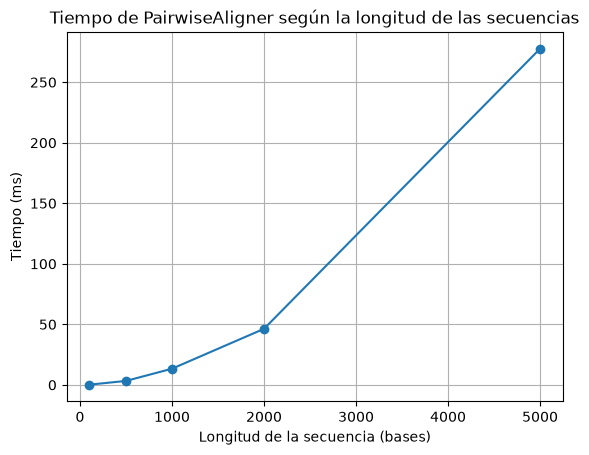

In [17]:
n = np.array(tamanos)
t = np.array(tiempos_ms)

plt.figure()
plt.plot(n, t, "o-")
plt.title("Tiempo de PairwiseAligner según la longitud de las secuencias")
plt.xlabel("Longitud de la secuencia (bases)")
plt.ylabel("Tiempo (ms)")
plt.grid()
plt.show()

### 3. ¿Qué crecimiento tiene? Exponente y extrapolación
Si el tiempo sigue `t = c · n^k`, entonces `log t = log c + k · log n`: en escala logarítmica es una recta y su pendiente es `k`. La calculamos con un ajuste lineal. Después extrapolamos a 1 millón de bases (el escenario del enunciado).

In [18]:
k, log_c = np.polyfit(np.log(n), np.log(t), 1)
print(f"Exponente estimado k = {k:.2f}")

n_grande = 1_000_000
t_grande_s = np.exp(log_c) * n_grande ** k / 1000
print(f"Tiempo estimado para 1.000.000 de bases: {t_grande_s:,.0f} s = {t_grande_s / 3600:,.1f} horas")

Exponente estimado k = 1.89
Tiempo estimado para 1.000.000 de bases: 6,148 s = 1.7 horas


### 4. Interpretación
(Los tiempos exactos cambian un poco en cada ejecución; la conclusión no.)
- **El tiempo no crece linealmente, crece de forma cuadrática**: el exponente estimado es ≈ 2 (entre 1,8 y 1,9 en nuestras ejecuciones). Al duplicar la longitud (de 1000 a 2000 bases) el tiempo se multiplica por ≈ 4.
- **Motivo:** la programación dinámica rellena una matriz de `n × m` celdas, una por cada pareja de posiciones. Con dos secuencias de longitud `n`, el coste es **O(n²)** en tiempo (y también en memoria, porque se guarda la matriz para poder reconstruir el alineamiento).
- **Escalabilidad:** alinear dos secuencias de 5000 bases cuesta menos de un segundo (≈ 0,3 s), pero la extrapolación a 1 millón de bases da **más de una hora para un solo par** (y una matriz de 10¹² celdas, inviable en memoria). Por tanto, el alineamiento exacto **no escala** a secuencias muy largas.
- **Matiz importante:** el enunciado habla de "100 datos a 1 millón de datos". Si lo que crece es el **número de pares** de secuencias cortas, el coste crece linealmente con el número de pares y es asumible (y paralelizable). El problema aparece cuando crece la **longitud** de cada secuencia.
- **Alternativas** cuando hace falta escalar: heurísticas como BLAST, que no rellenan toda la matriz (a costa de no garantizar el óptimo), o alineamiento por bandas.